# Training a neural solver on simulated paths

A terminal-matching objective is:

$$
\mathcal L(\theta,y_0,z_0)=\frac1M\sum_{m=1}^{M}\left|g\!\left(X_N^{(m)}\right)-Y_N^{(m)}(\theta,y_0,z_0)\right|^2.
$$

Here, $\theta$ contains the network weights; $y_0$ is the initial value estimate; $z_0$ is the initial control when it is learned separately; $M$ is the number of generated paths; $m$ labels a path; $N$ is the final time index; $g(X_N^{(m)})$ is the terminal value; and $Y_N^{(m)}$ is the value produced by the stepwise backward calculation.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
from pathlib import Path
import inspect
import math
import re
import sys
import time
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image

warnings.filterwarnings("ignore")
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
ROOT = Path.cwd().parents[1]

from RiskLabAI.pde import BlackScholesBarenblatt, DeepBSDE, DeepTimeSetTransformer, Equation, FBSDESolver, FBSNNNetwork, FBSNNolver, FBSNNSolver, HJBLQ, ISAB, MAB, Net1, PMA, PricingDefaultRisk, PricingDiffRate, SAB, TimeDependentNetwork, TimeDependentNetworkMonteCarlo, TimeNet, TimeNetForSet, initialize_weights

FIGURES = ROOT / "outputs" / "figures" / "29_deep_bsde"
TABLES = ROOT / "outputs" / "tables" / "29_deep_bsde"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def count_parameters(model):
    return int(sum(parameter.numel() for parameter in model.parameters()))

def finite_sequence(values):
    array = np.asarray(values, dtype=float)
    return bool(array.size and np.all(np.isfinite(array)))

device = torch.device("cpu")



def layer_sizes_for(pde, method, width):
    if method == "DeepBSDE":
        return [pde.dim, width, width, pde.dim]
    return [width, width]

def run_fbsde(pde, method, seed, iterations, batch_size, width, learning_rate):
    np.random.seed(seed)
    torch.manual_seed(seed)
    solver = FBSDESolver(pde=pde, layer_sizes=layer_sizes_for(pde, method, width), learning_rate=learning_rate, solving_method=method, device=device)
    started = time.perf_counter()
    losses, estimates = solver.solve(num_iterations=iterations, batch_size=batch_size, init_y=float(pde.y_init if pde.y_init is not None else 0.0))
    elapsed = time.perf_counter() - started
    return {"losses": np.asarray(losses, dtype=float), "estimates": np.asarray(estimates, dtype=float), "seconds": elapsed, "parameters": count_parameters(solver.solver)}

def run_fbsnn(pde, seed, iterations, batch_size, width, learning_rate):
    np.random.seed(seed)
    torch.manual_seed(seed)
    solver = FBSNNSolver(pde=pde, layer_sizes=[pde.dim + 1, width, width, 1], learning_rate=learning_rate, device=device)
    dw_validation, x_validation = pde.sample(128)
    x_validation = torch.tensor(x_validation, dtype=torch.float32, device=device)
    dw_validation = torch.tensor(dw_validation, dtype=torch.float32, device=device)
    t_validation = torch.ones((128, 1), device=device)
    dummy = torch.tensor(0.0, device=device)
    losses = []
    estimates = []
    started = time.perf_counter()
    for _ in range(iterations):
        dw_training, x_training = pde.sample(batch_size)
        x_training = torch.tensor(x_training, dtype=torch.float32, device=device)
        dw_training = torch.tensor(dw_training, dtype=torch.float32, device=device)
        t_training = torch.ones((batch_size, 1), device=device)
        solver.optimizer.zero_grad()
        loss = solver.compute_loss(x_training, dw_training, t_training, dummy)
        loss.backward()
        solver.optimizer.step()
        with torch.enable_grad():
            validation_loss = solver.compute_loss(x_validation.detach(), dw_validation, t_validation, dummy)
        with torch.no_grad():
            initial_state = x_validation[:, :, 0]
            initial_time = torch.zeros((128, 1), device=device)
            initial_value = solver.solver(torch.cat((initial_time, initial_state), dim=1)).mean()
        losses.append(float(validation_loss.detach().cpu()))
        estimates.append(float(initial_value.detach().cpu()))
    elapsed = time.perf_counter() - started
    return {"losses": np.asarray(losses, dtype=float), "estimates": np.asarray(estimates, dtype=float), "seconds": elapsed, "parameters": count_parameters(solver.solver)}

def run_method(pde, method, seed, iterations, batch_size, width):
    if method == "FBSNN":
        return run_fbsnn(pde, seed, iterations, batch_size, width, 0.001)
    learning_rate = 0.005 if method == "DTNN" else 0.01
    return run_fbsde(pde, method, seed, iterations, batch_size, width, learning_rate)

def summarize_histories(histories, reference=None):
    rows = []
    for method in sorted({item["method"] for item in histories}):
        selected = [item for item in histories if item["method"] == method]
        final_values = np.array([item["estimates"][-1] for item in selected])
        final_losses = np.array([item["losses"][-1] for item in selected])
        row = {"Method": method, "Runs": len(selected), "Initial value mean": final_values.mean(), "Initial value standard deviation": final_values.std(ddof=1) if len(selected) > 1 else 0.0, "Final loss mean": final_losses.mean(), "Final loss standard deviation": final_losses.std(ddof=1) if len(selected) > 1 else 0.0, "Mean run time seconds": np.mean([item["seconds"] for item in selected]), "Parameters": selected[0]["parameters"]}
        if reference is not None and np.isfinite(reference):
            row["Absolute error"] = abs(row["Initial value mean"] - reference)
            row["Relative error"] = row["Absolute error"] / max(abs(reference), 1e-12)
        rows.append(row)
    return pd.DataFrame(rows)

def plot_method_histories(histories, reference, stem, title):
    methods = [method for method in ("DTNN", "DeepBSDE", "FBSNN") if any(item["method"] == method for item in histories)]
    colors = {"DTNN": palette["green"], "DeepBSDE": palette["cyan"], "FBSNN": palette["rose"]}
    figure, axes = plt.subplots(1, 2, figsize=(11.2, 4.1))
    for method in methods:
        selected = [item for item in histories if item["method"] == method]
        estimates = np.vstack([item["estimates"] for item in selected])
        losses = np.vstack([item["losses"] for item in selected])
        steps = np.arange(1, estimates.shape[1] + 1)
        mean_estimate = estimates.mean(axis=0)
        std_estimate = estimates.std(axis=0)
        mean_loss = losses.mean(axis=0)
        std_loss = losses.std(axis=0)
        axes[0].plot(steps, mean_estimate, color=colors[method], linewidth=1.9, label=method)
        axes[0].fill_between(steps, mean_estimate - std_estimate, mean_estimate + std_estimate, color=colors[method], alpha=0.18)
        axes[1].plot(steps, np.maximum(mean_loss, 1e-12), color=colors[method], linewidth=1.9, label=method)
        axes[1].fill_between(steps, np.maximum(mean_loss - std_loss, 1e-12), np.maximum(mean_loss + std_loss, 1e-12), color=colors[method], alpha=0.18)
    if reference is not None and np.isfinite(reference):
        axes[0].axhline(reference, color=palette["amber"], linestyle="--", linewidth=1.8, label="Reference")
    axes[0].set_xlabel("Training round")
    axes[0].set_ylabel("Initial value estimate")
    axes[0].set_title(title)
    axes[1].set_xlabel("Training round")
    axes[1].set_ylabel("Terminal loss")
    axes[1].set_yscale("log")
    axes[1].set_title("Validation loss")
    for axis in axes:
        axis.grid(True, alpha=0.45)
        axis.legend()
    figure.tight_layout()
    save_figure(figure, stem)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Three Neural Constructions

DeepBSDE approximates the control at each time by a separate network:

$$
Z_n\approx\mathcal Z_{\theta_n}(X_n),
\qquad
Y_{n+1}=Y_n+f_n\Delta t+Z_n^{\mathsf T}\Delta W_n.
$$

Here, $\mathcal Z_{\theta_n}$ is the network used at time index $n$; $\theta_n$ is its weight vector; $Z_n$ is the estimated control; $Y_n$ is the estimated value; $f_n$ is the driver evaluated at the current state; and $\Delta W_n$ is the Brownian increment.

The time-dependent network changes each hidden representation with a learned function of time:

$$
h_{\ell+1}=\sin\!\left(A_{\ell}\left[h_{\ell}\odot\left(1+q_{\ell}(t)\right)\right]+b_{\ell}\right),
\qquad Z_t=A_Lh_L+b_L.
$$

Here, $h_{\ell}$ is the hidden vector at layer $\ell$; $q_{\ell}(t)$ is the learned time transformation; $A_{\ell}$ and $b_{\ell}$ are weights and offsets; $\odot$ is elementwise multiplication; $Z_t$ is the final control estimate; and $L$ is the number of hidden layers.

FBSNN represents the value itself and obtains the control by differentiation:

$$
Y_n=U_{\theta}(t_n,X_n),
\qquad
Z_n=\sigma(t_n,X_n)^{\mathsf T}\nabla_xU_{\theta}(t_n,X_n).
$$

Here, $U_{\theta}$ is one network shared across time; $t_n$ and $X_n$ are the current time and state; $Y_n$ is the predicted value; $\nabla_xU_{\theta}$ is the gradient with respect to the state; $\sigma$ is the diffusion matrix; and $Z_n$ is the resulting Brownian exposure.

In [2]:
architecture_table = pd.DataFrame([
    {"Method": "DeepBSDE", "Learned quantity": "Control at each time", "Time treatment": "Separate network by time", "Initial value": "Learned scalar", "Validation derivatives needed": False},
    {"Method": "DTNN", "Learned quantity": "Time-dependent control", "Time treatment": "Time transformation in hidden layers", "Initial value": "Recovered from generated paths", "Validation derivatives needed": False},
    {"Method": "FBSNN", "Learned quantity": "Value as a function of time and state", "Time treatment": "Time is a network input", "Initial value": "Network value at the initial state", "Validation derivatives needed": True},
])
save_table(architecture_table, "neural_method_architecture", "The three neural constructions used in the chapter comparisons.", "tab:chapter29-neural-architecture")
display(architecture_table)

equation = HJBLQ({"dim": 5, "total_time": 1.0, "num_time_interval": 10})
equation.y_init = 0.0
model_rows = []
deep_model = torch.nn.ModuleList([DeepBSDE([equation.dim, 16, 16, equation.dim]) for _ in range(equation.num_time_interval)])
dtnn_model = TimeDependentNetwork(equation.dim, [16, 16], equation.dim)
fbsnn_model = FBSNNNetwork([equation.dim + 1, 16, 16, 1])
for name, model in (("DeepBSDE", deep_model), ("DTNN", dtnn_model), ("FBSNN", fbsnn_model)):
    model_rows.append({"Method": name, "Trainable parameters": count_parameters(model), "Networks across time": equation.num_time_interval if name == "DeepBSDE" else 1})
parameter_table = pd.DataFrame(model_rows)
save_table(parameter_table, "method_parameter_counts", "Trainable parameter counts for the five-dimensional comparison.", "tab:chapter29-parameter-counts")
display(parameter_table)

,Method,Learned quantity,Time treatment,Initial value,Validation derivatives needed
0,DeepBSDE,Control at each time,Separate network by time,Learned scalar,False
1,DTNN,Time-dependent control,Time transformation in hidden layers,Recovered from generated paths,False
2,FBSNN,Value as a function of time and state,Time is a network input,Network value at the initial state,True


,Method,Trainable parameters,Networks across time
0,DeepBSDE,5000,10
1,DTNN,504877,1
2,FBSNN,401,1


## What released paths can establish

In [3]:
def path_result(name, action, expected, stopped_message):
    try:
        action()
        return {"Path": name, "Observed result": "Completed", "Expected in this release": expected, "Message": "Returned finite histories"}
    except Exception:
        return {"Path": name, "Observed result": "Stopped", "Expected in this release": expected, "Message": stopped_message}

def one_fbsde(method):
    local = HJBLQ({"dim": 2, "total_time": 1.0, "num_time_interval": 3})
    local.y_init = 0.0
    layers = [local.dim, 8, local.dim] if method == "DeepBSDE" else [8]
    solver = FBSDESolver(local, layers, 0.001, method, device)
    return solver.solve(1, 8, 0.0)

def one_released_fbsnn():
    local = HJBLQ({"dim": 2, "total_time": 1.0, "num_time_interval": 3})
    solver = FBSNNSolver(local, [3, 8, 1], 0.001, device)
    return solver.solve(1, 8, 0.0)

def one_notebook_fbsnn():
    local = HJBLQ({"dim": 2, "total_time": 1.0, "num_time_interval": 3})
    local.y_init = 0.0
    result = run_fbsnn(local, 2902, 2, 8, 8, 0.001)
    assert finite_sequence(result["losses"])
    return result

path_rows = [
    path_result("DTNN in the released calculation", lambda: one_fbsde("DTNN"), "Complete", "Unexpected stop"),
    path_result("DeepBSDE in the released calculation", lambda: one_fbsde("DeepBSDE"), "Complete", "Unexpected stop"),
    path_result("Monte Carlo in the released calculation", lambda: one_fbsde("Monte-Carlo"), "Stop", "The required Monte Carlo control value is not supplied"),
    path_result("Set-based network in the released calculation", lambda: one_fbsde("Deep-Time-SetTransformer"), "Stop", "The state shape does not match the set-shaped input"),
    path_result("FBSNN in the released calculation", one_released_fbsnn, "Stop", "The validation step turns off required derivatives"),
    path_result("FBSNN with validation derivatives retained", one_notebook_fbsnn, "Complete", "Unexpected stop"),
]
path_table = pd.DataFrame(path_rows)
save_table(path_table, "released_solver_path_status", "Observed results for every released solution path and the notebook-level FBSNN procedure.", "tab:chapter29-path-status")
display(path_table)

,Path,Observed result,Expected in this release,Message
0,DTNN in the released calculation,Completed,Complete,Returned finite histories
1,DeepBSDE in the released calculation,Completed,Complete,Returned finite histories
2,Monte Carlo in the released calculation,Stopped,Stop,The required Monte Carlo control value is not ...
3,Set-based network in the released calculation,Stopped,Stop,The state shape does not match the set-shaped ...
4,FBSNN in the released calculation,Stopped,Stop,The validation step turns off required derivat...
5,FBSNN with validation derivatives retained,Completed,Complete,Returned finite histories


## Repeated HJB Training

,Benchmark,Reference value,Monte Carlo standard error,Reference draws
0,Five-dimensional HJB,1.356406,0.001419,240000


,Method,Seed,Final initial value,Final terminal loss,Absolute error,Run time seconds,Parameters
0,DTNN,11,0.734863,1.950796,0.621543,1.111025,504877
1,DTNN,29,0.734346,2.052509,0.62206,1.031008,504877
2,DTNN,47,0.826735,1.927435,0.529671,1.198939,504877
3,DeepBSDE,11,1.461584,0.284892,0.105178,0.209043,5000
4,DeepBSDE,29,1.499656,0.193721,0.14325,0.244744,5000
5,DeepBSDE,47,1.498541,0.196689,0.142135,0.178926,5000
6,FBSNN,11,0.627406,1.352628,0.729,0.511345,401
7,FBSNN,29,0.572337,1.171643,0.784069,0.446273,401
8,FBSNN,47,0.453254,1.438981,0.903152,0.546642,401


,Method,Runs,Initial value mean,Initial value standard deviation,Final loss mean,Final loss standard deviation,Mean run time seconds,Parameters,Absolute error,Relative error
0,DTNN,3,0.765315,0.053192,1.976913,0.066502,1.113658,504877,0.591091,0.435778
1,DeepBSDE,3,1.486594,0.021667,0.225101,0.051802,0.210904,5000,0.130188,0.09598
2,FBSNN,3,0.550999,0.089015,1.321084,0.136432,0.50142,401,0.805407,0.59378


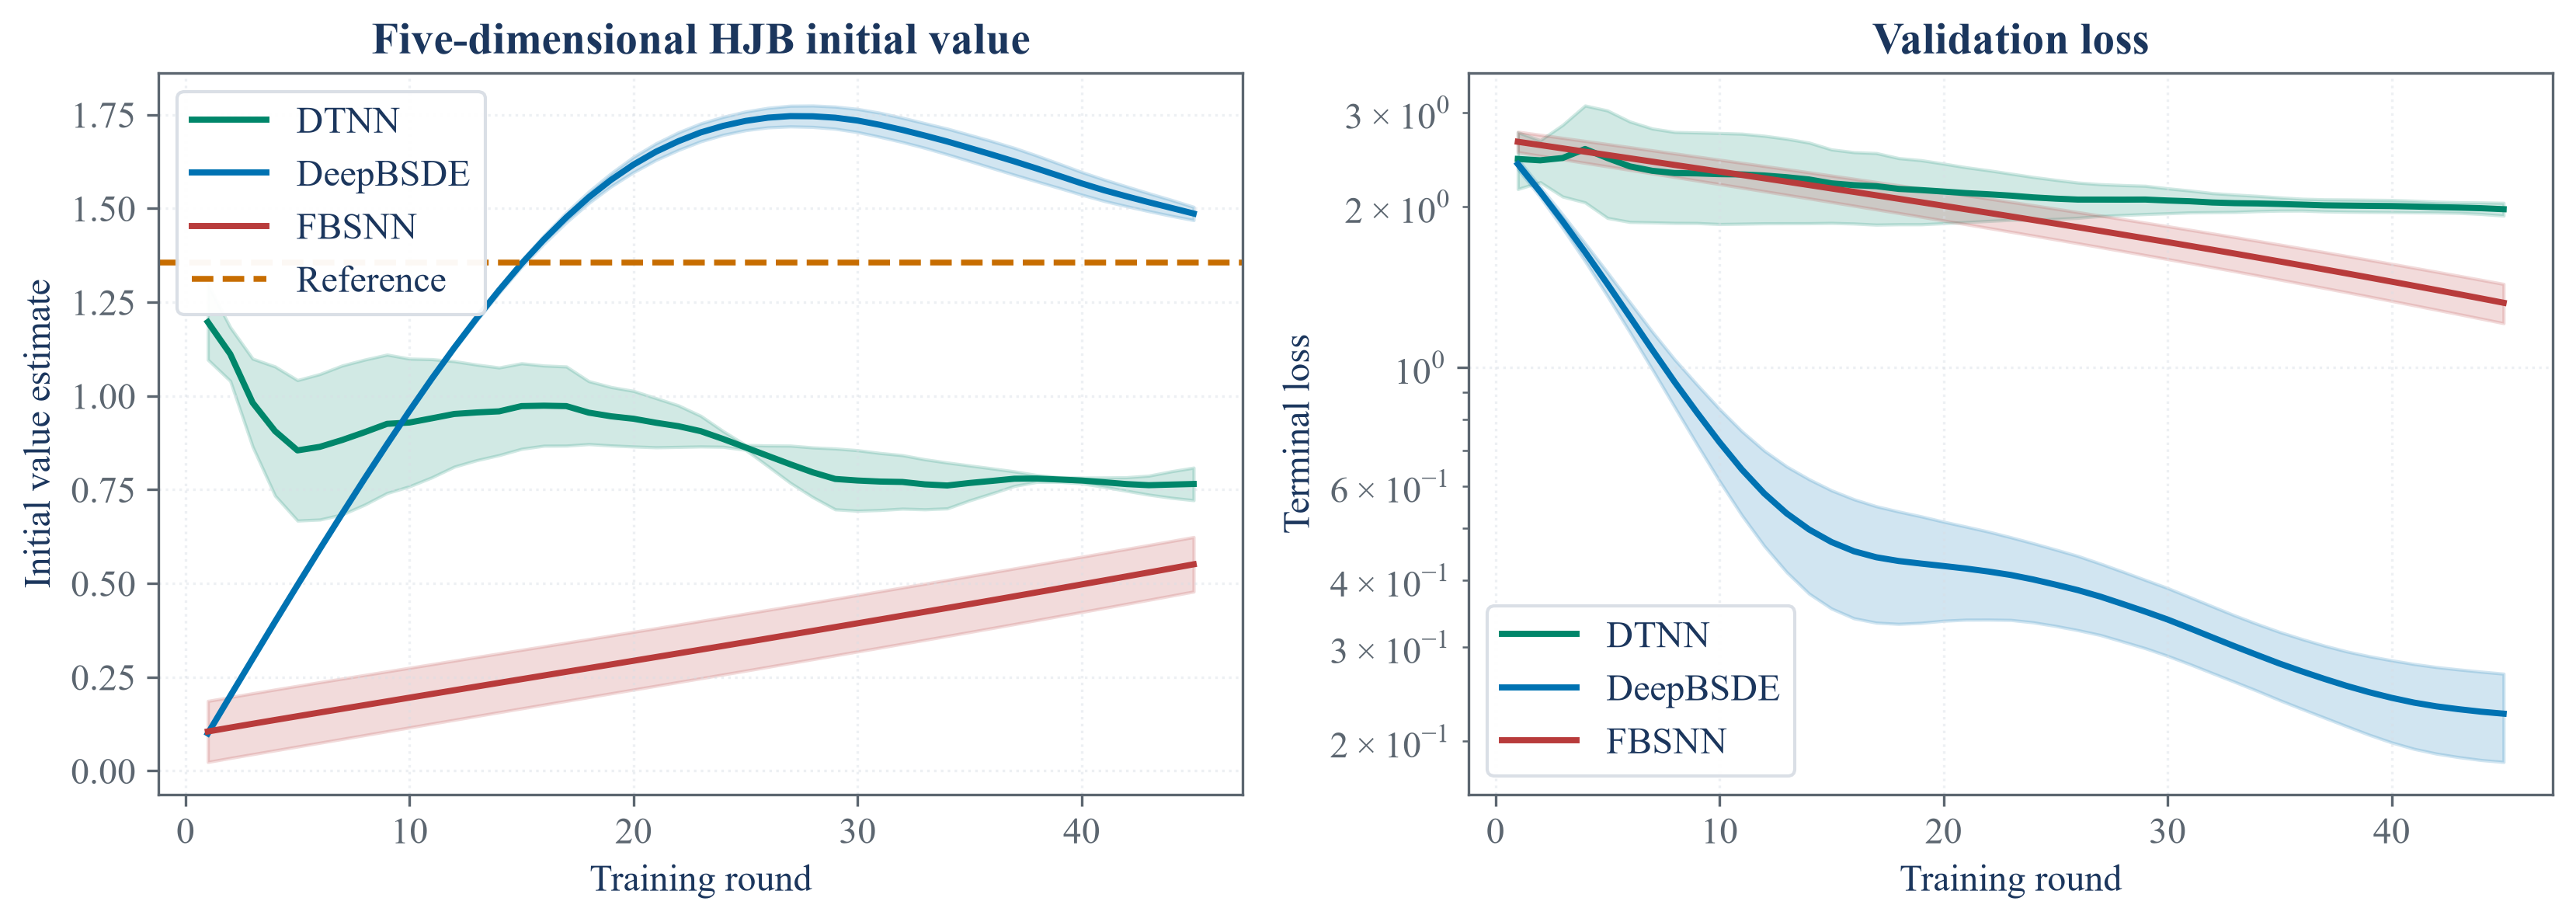

In [4]:
def hjb_reference(dimension, horizon, draws, seed):
    rng = np.random.default_rng(seed)
    total = 0.0
    total_square = 0.0
    observed = 0
    for start in range(0, draws, 20000):
        count = min(20000, draws - start)
        terminal = np.sqrt(2.0 * horizon) * rng.standard_normal((count, dimension))
        transformed = 2.0 / (1.0 + np.sum(terminal**2, axis=1))
        total += transformed.sum()
        total_square += np.square(transformed).sum()
        observed += count
    mean = total / observed
    variance = (total_square - observed * mean**2) / (observed - 1)
    value = -np.log(mean)
    standard_error = np.sqrt(variance / observed) / mean
    return value, standard_error

reference, reference_error = hjb_reference(5, 1.0, 240000, 2903)
histories = []
for method in ("DTNN", "DeepBSDE", "FBSNN"):
    for seed in (11, 29, 47):
        local = HJBLQ({"dim": 5, "total_time": 1.0, "num_time_interval": 10})
        local.y_init = 0.0
        result = run_method(local, method, seed, 45, 64, 16)
        result.update({"method": method, "seed": seed})
        histories.append(result)
run_rows = []
for item in histories:
    run_rows.append({"Method": item["method"], "Seed": item["seed"], "Final initial value": item["estimates"][-1], "Final terminal loss": item["losses"][-1], "Absolute error": abs(item["estimates"][-1] - reference), "Run time seconds": item["seconds"], "Parameters": item["parameters"]})
run_table = pd.DataFrame(run_rows)
summary_table = summarize_histories(histories, reference)
reference_table = pd.DataFrame([{"Benchmark": "Five-dimensional HJB", "Reference value": reference, "Monte Carlo standard error": reference_error, "Reference draws": 240000}])
save_table(run_table, "hjb_repeated_runs", "Repeated five-dimensional HJB training runs.", "tab:chapter29-hjb-runs")
save_table(summary_table, "hjb_method_summary", "Mean and dispersion across repeated HJB runs.", "tab:chapter29-hjb-summary")
save_table(reference_table, "hjb_reference", "Independent Monte Carlo reference for the five-dimensional HJB comparison.", "tab:chapter29-hjb-reference")
display(reference_table)
display(run_table)
display(summary_table)
plot_method_histories(histories, reference, "hjb_method_training", "Five-dimensional HJB initial value")

## Distinguishing training loss from solution error

,Method,Training rounds,Initial value,Terminal loss,Absolute error
0,DTNN,5,0.854869,2.463556,0.501537
1,DTNN,15,0.972995,2.209776,0.383411
2,DTNN,30,0.77452,2.052131,0.581886
3,DTNN,45,0.765315,1.976913,0.591091
4,DeepBSDE,5,0.495559,1.432535,0.860847
5,DeepBSDE,15,1.35267,0.471453,0.009502
6,DeepBSDE,30,1.734575,0.337689,0.378169
7,DeepBSDE,45,1.486594,0.225101,0.130188
8,FBSNN,5,0.145874,2.496714,1.210532
9,FBSNN,15,0.244745,2.161452,1.111661


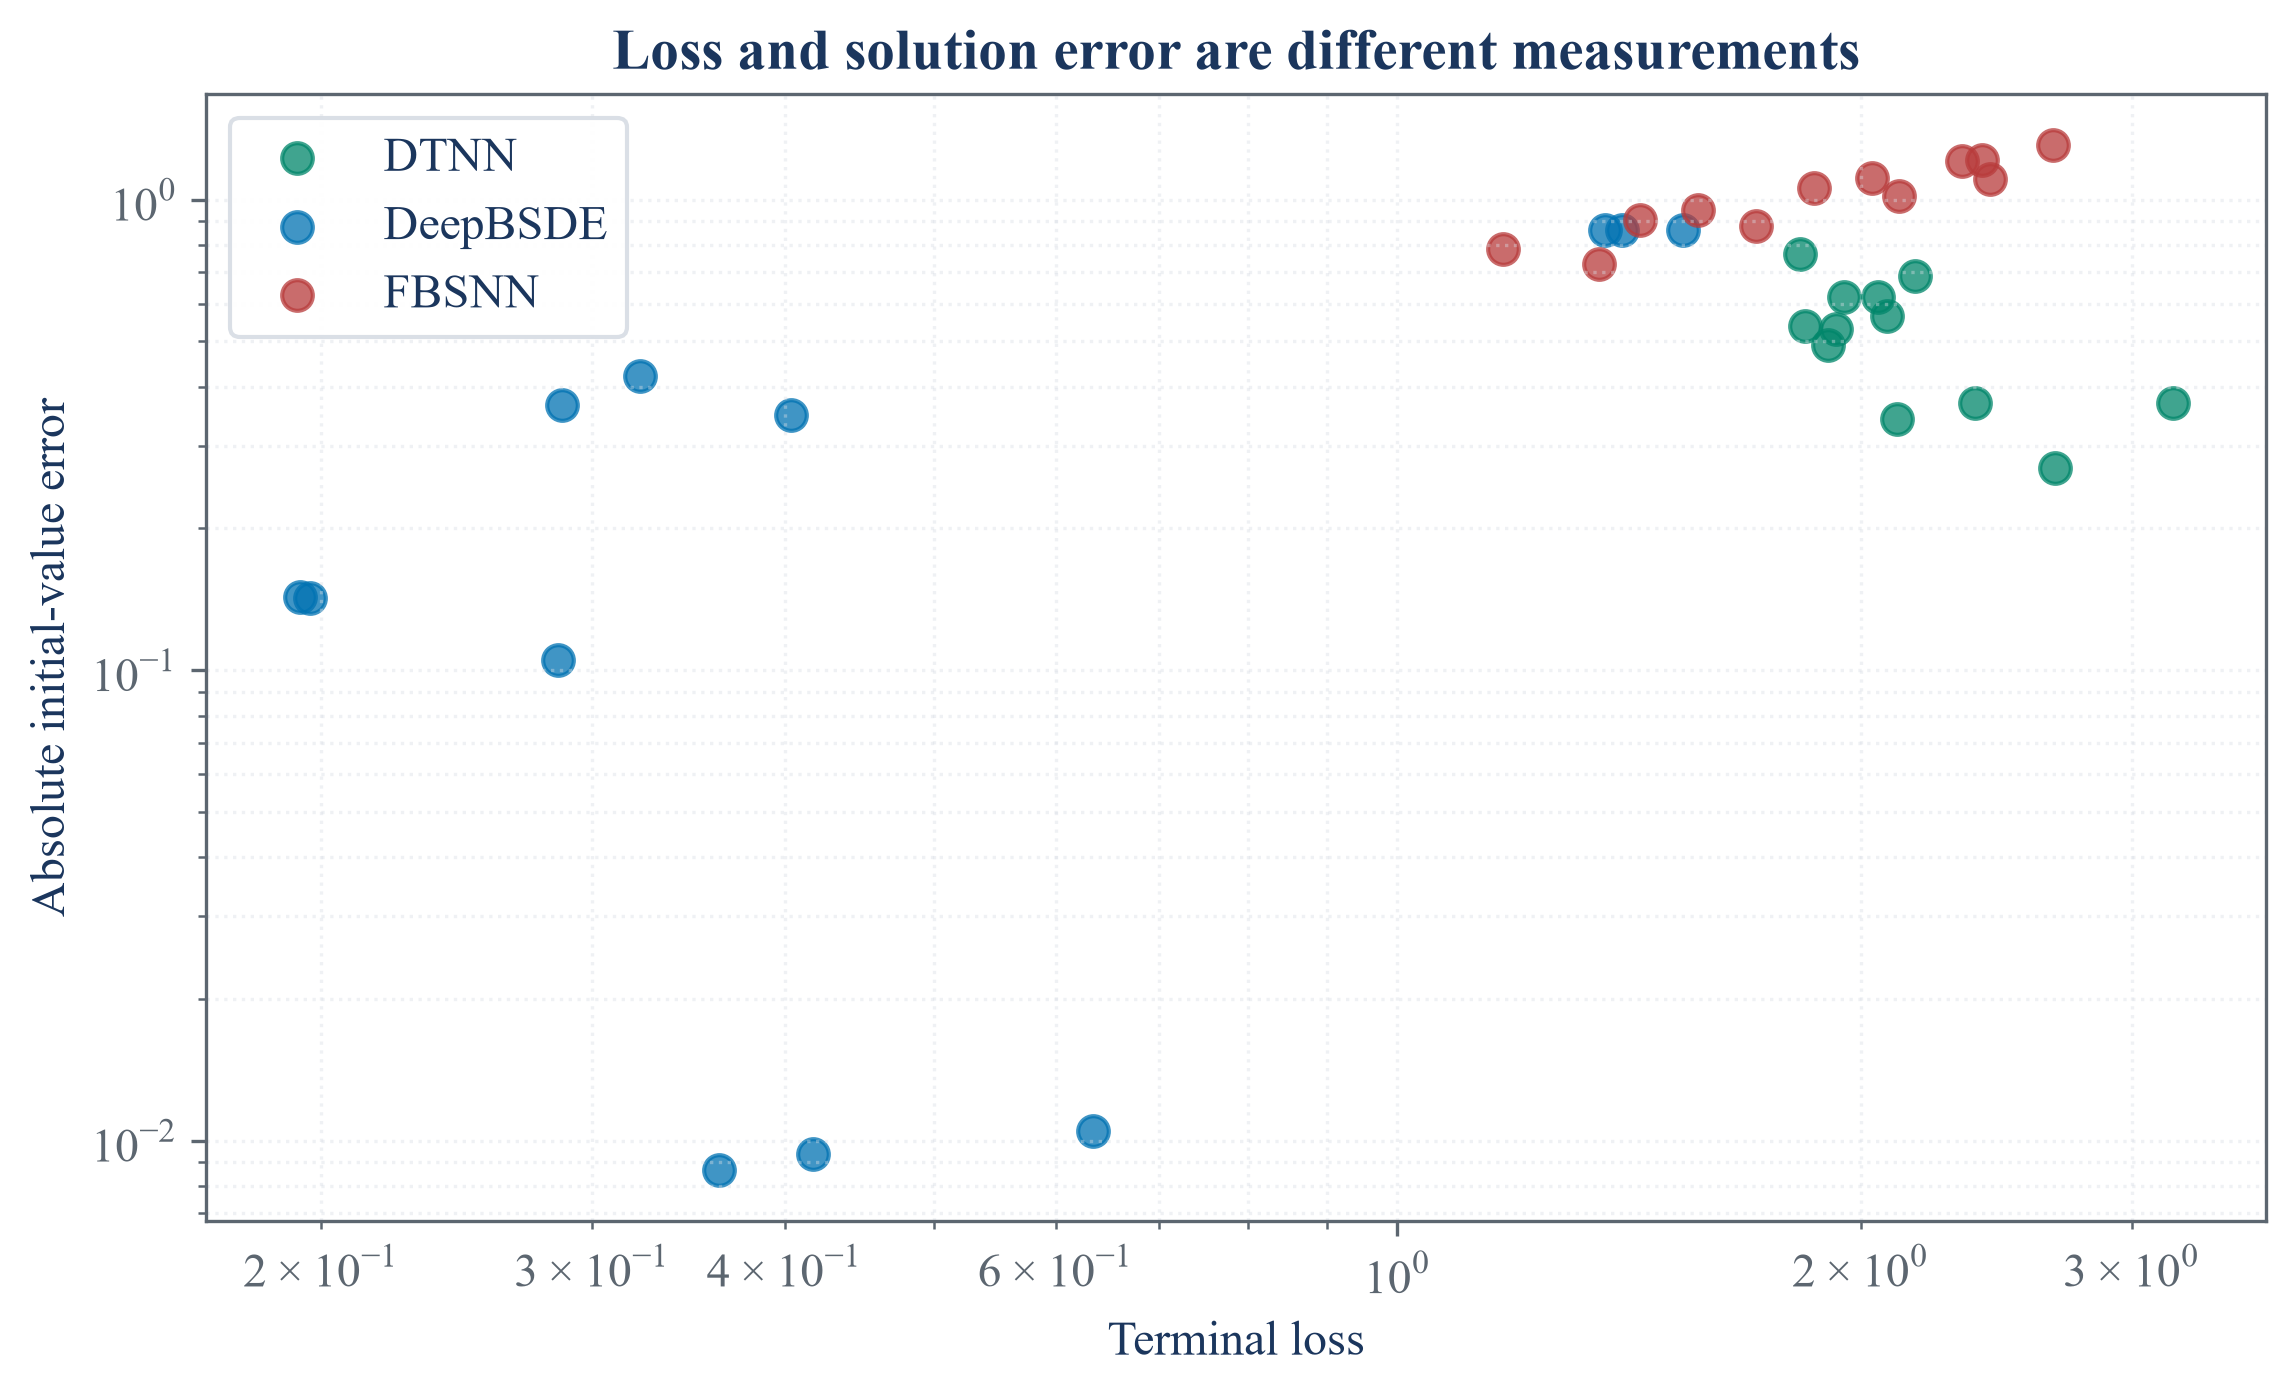

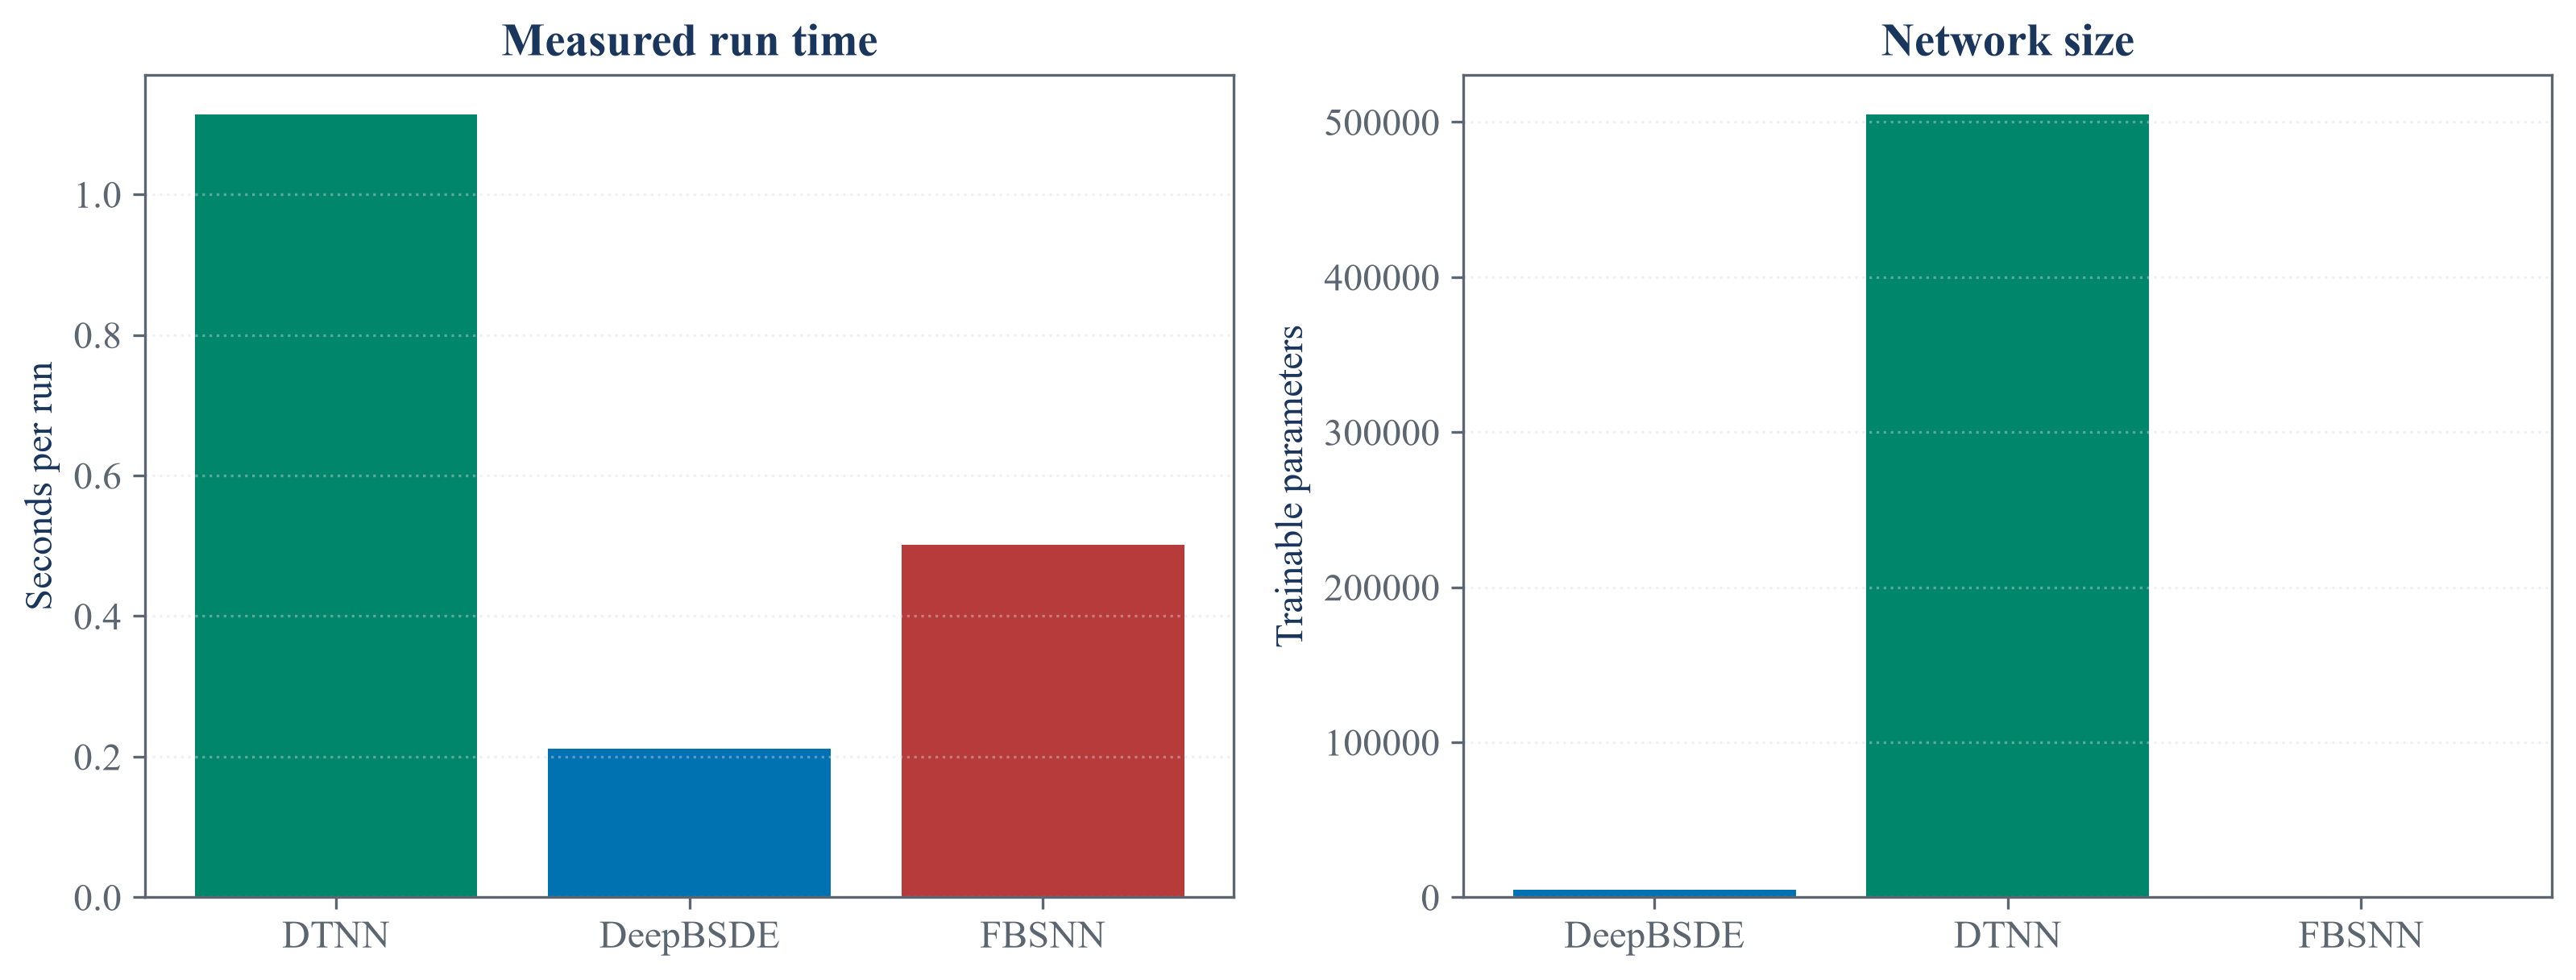

In [5]:
checkpoint_rows = []
for item in histories:
    for checkpoint in (5, 15, 30, 45):
        checkpoint_rows.append({"Method": item["method"], "Seed": item["seed"], "Training rounds": checkpoint, "Initial value": item["estimates"][checkpoint - 1], "Terminal loss": item["losses"][checkpoint - 1], "Absolute error": abs(item["estimates"][checkpoint - 1] - reference)})
checkpoint_table = pd.DataFrame(checkpoint_rows)
budget_table = checkpoint_table.groupby(["Method", "Training rounds"], as_index=False).agg({"Initial value": "mean", "Terminal loss": "mean", "Absolute error": "mean"})
save_table(budget_table, "hjb_training_budget", "HJB loss and solution error at four training budgets.", "tab:chapter29-hjb-budget")
display(budget_table)

figure, axis = plt.subplots(figsize=(7.8, 4.8))
color_map = {"DTNN": palette["green"], "DeepBSDE": palette["cyan"], "FBSNN": palette["rose"]}
for method, group in checkpoint_table.groupby("Method"):
    axis.scatter(group["Terminal loss"], group["Absolute error"], s=54, alpha=0.75, color=color_map[method], label=method)
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel("Terminal loss")
axis.set_ylabel("Absolute initial-value error")
axis.set_title("Loss and solution error are different measurements")
axis.grid(True, which="both", alpha=0.4)
axis.legend()
figure.tight_layout()
save_figure(figure, "hjb_loss_error_relation")

figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.2))
axes[0].bar(summary_table["Method"], summary_table["Mean run time seconds"], color=[color_map[item] for item in summary_table["Method"]])
axes[0].set_ylabel("Seconds per run")
axes[0].set_title("Measured run time")
axes[0].grid(True, axis="y", alpha=0.4)
axes[1].bar(parameter_table["Method"], parameter_table["Trainable parameters"], color=[color_map[item] for item in parameter_table["Method"]])
axes[1].set_ylabel("Trainable parameters")
axes[1].set_title("Network size")
axes[1].grid(True, axis="y", alpha=0.4)
figure.tight_layout()
save_figure(figure, "method_time_and_size")

## Adam Updates

Adam uses moving first and second moments of the stochastic gradient:

$$
m_k=\beta_1m_{k-1}+(1-\beta_1)g_k,
\qquad
v_k=\beta_2v_{k-1}+(1-\beta_2)g_k^2,
\qquad
\theta_k=\theta_{k-1}-\alpha\frac{\widehat m_k}{\sqrt{\widehat v_k}+\varepsilon}.
$$

Here, $k$ is the update number; $g_k$ is the current gradient; $m_k$ and $v_k$ are moving first and second raw moments; $\beta_1$ and $\beta_2$ are decay values; $\widehat m_k$ and $\widehat v_k$ are bias-corrected moments; $\alpha$ is the learning rate; $\varepsilon$ is a small positive stabilizer; and $\theta_k$ is the updated weight vector.

## Tests

In [6]:
outcome = dict(zip(path_table["Path"], path_table["Observed result"]))
assert outcome["DTNN in the released calculation"] == "Completed"
assert outcome["DeepBSDE in the released calculation"] == "Completed"
assert outcome["Monte Carlo in the released calculation"] == "Stopped"
assert outcome["Set-based network in the released calculation"] == "Stopped"
assert outcome["FBSNN in the released calculation"] == "Stopped"
assert outcome["FBSNN with validation derivatives retained"] == "Completed"
assert len(histories) == 9
assert all(finite_sequence(item["losses"]) and finite_sequence(item["estimates"]) for item in histories)
assert np.isfinite(reference) and reference_error > 0
assert set(run_table["Method"]) == {"DTNN", "DeepBSDE", "FBSNN"}
assert parameter_table["Trainable parameters"].gt(0).all()
display(pd.DataFrame({"Test": ["Released DTNN", "Released DeepBSDE", "Monte Carlo failure exposed", "Set-based failure exposed", "Released FBSNN failure exposed", "Notebook FBSNN", "Repeated finite runs", "Independent reference"], "Passed": [True, True, True, True, True, True, True, True]}))

,Test,Passed
0,Released DTNN,True
1,Released DeepBSDE,True
2,Monte Carlo failure exposed,True
3,Set-based failure exposed,True
4,Released FBSNN failure exposed,True
5,Notebook FBSNN,True
6,Repeated finite runs,True
7,Independent reference,True
